# Khảo sát khả thi gán nhãn — Southampton

## Giới thiệu dữ liệu

Southampton là dữ liệu IMU của mô hình KCS quy mô thử nghiệm; 47 run có cửa sổ 60 giây nhưng chỉ Run 14 đủ 180 giây. Wave frequency/amplitude trong Test Plan là bối cảnh thí nghiệm, không tự động là nhãn hazard.

Notebook tái sử dụng `ml.labeling.feasibility.load_eligible_windows` và artifact do pipeline tạo. Không áp dụng ngưỡng mới, không tạo ground truth, không huấn luyện mô hình.

In [1]:
DATASET = "southampton"
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
import sys

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/labeling/config.yaml").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/labeling/config.yaml").is_file())
sys.path.insert(0, str(REPO_ROOT))
from ml.labeling.feasibility import load_eligible_windows
SUMMARY = json.loads((REPO_ROOT / "ml/reports/labeling/labeling_summary.json").read_text(encoding="utf-8"))
WINDOWS = load_eligible_windows(REPO_ROOT / "ml/data/features", (DATASET,))
FRAME = WINDOWS[DATASET]
print(f"Nguồn: {DATASET}; cửa sổ 180 giây đủ 23 feature góc: {len(FRAME):,}; session: {FRAME.session_id.nunique()}; segment: {FRAME.segment_id.nunique()}")

Nguồn: southampton; cửa sổ 180 giây đủ 23 feature góc: 34; session: 1; segment: 1


## Cơ sở phương pháp

Cửa sổ lịch sử dùng quy ước `(t-180,t]`, tách theo session/segment và phải có toàn bộ 23 feature góc ở trạng thái `VALID`. Stride hiện hành 10 giây khiến các cửa sổ kề nhau chồng lấn khoảng 94,4%. Các percentile bên dưới chỉ mô tả dữ liệu; chúng không phải ngưỡng phân loại.

In [2]:
metric_columns = ["roll_mean_180", "roll_std_60", "roll_rms_60", "roll_peak_to_peak_60", "roll_rms_slope_180", "roll_rms_trend_r2_180", "pitch_rms_60"]
rows = []
for feature in metric_columns:
    values = pd.to_numeric(FRAME[feature], errors="coerce").dropna()
    rows.append({"Đặc trưng": feature, "Số mẫu": len(values), "Trung bình": values.mean(),
                 "Độ lệch chuẩn tổng thể": values.std(ddof=0), "Nhỏ nhất": values.min(),
                 "P05": values.quantile(.05), "Trung vị": values.quantile(.5),
                 "P95": values.quantile(.95), "Lớn nhất": values.max()})
display(pd.DataFrame(rows).set_index("Đặc trưng"))

,Số mẫu,Trung bình,Độ lệch chuẩn tổng thể,Nhỏ nhất,P05,Trung vị,P95,Lớn nhất
Đặc trưng,,,,,,,,
roll_mean_180,34,0.693601,0.007508,0.680191,0.682000,0.692090,0.705837,0.707232
roll_std_60,34,0.031856,0.030440,0.011751,0.012301,0.017848,0.106546,0.119906
roll_rms_60,34,0.698261,0.013201,0.676397,0.677368,0.695234,0.718264,0.722417
roll_peak_to_peak_60,34,0.184113,0.182090,0.062853,0.067059,0.084914,0.626285,0.626285
roll_rms_slope_180,34,0.004606,0.009037,-0.017222,-0.012918,0.007083,0.014584,0.016504
roll_rms_trend_r2_180,34,0.611430,0.342588,0.022491,0.094015,0.767161,0.982165,0.998630
pitch_rms_60,34,1.775681,0.025195,1.717475,1.738684,1.778040,1.814033,1.819267


## Kiểm tra lớp mục tiêu và khả năng bao phủ

`HIGH_ROLL` cần ngưỡng dao động được biện minh độc lập và phải tách offset tĩnh; `PERSISTENT_OFFSET` cần datum/góc nền và tiêu chí ổn định dấu; `AMPLITUDE_GROWTH` cần tiêu chuẩn tăng trưởng; `NORMAL` cần operating envelope được chấp nhận. Hiện chưa có các tiêu chí đó. Vắng mặt của nhãn bất thường không tạo ra `NORMAL`.

In [3]:
dataset_summary = SUMMARY["datasets"][DATASET]
status = pd.DataFrame([{"Lớp": label, "Số nhãn xác minh": 0, "Session hỗ trợ": 0, "Kết luận": "Chưa đủ bằng chứng độc lập"}
                      for label in ("NORMAL", "HIGH_ROLL", "PERSISTENT_OFFSET", "AMPLITUDE_GROWTH")])
display(status)
label_dir = REPO_ROOT / "ml/data/labels/feasibility" / DATASET
partition_counts = {}
for filename, caption in (("candidate_labels.parquet", "Proxy candidate"), ("unlabeled_windows.parquet", "Chưa gán nhãn"),
                          ("review_required_windows.parquet", "Cần review"), ("verified_reviewed_annotations.parquet", "Đã xác minh/review") ):
    partition_counts[caption] = len(pd.read_parquet(label_dir / filename))
display(pd.Series(partition_counts, name="Số cửa sổ").to_frame())
print(f"Số cửa sổ đủ điều kiện: {dataset_summary['eligible_windows_180s_angle23']:,}; session hỗ trợ: {dataset_summary['sessions_with_eligible_windows']}; review decision đã nhập: {SUMMARY['human_review_decisions']}")

,Lớp,Số nhãn xác minh,Session hỗ trợ,Kết luận
0,NORMAL,0,0,Chưa đủ bằng chứng độc lập
1,HIGH_ROLL,0,0,Chưa đủ bằng chứng độc lập
2,PERSISTENT_OFFSET,0,0,Chưa đủ bằng chứng độc lập
3,AMPLITUDE_GROWTH,0,0,Chưa đủ bằng chứng độc lập


,Số cửa sổ
Proxy candidate,0
Chưa gán nhãn,34
Cần review,0
Đã xác minh/review,0


Số cửa sổ đủ điều kiện: 34; session hỗ trợ: 1; review decision đã nhập: 0


## Cửa sổ thực tế và phân tích chẩn đoán

Hình dưới đây lấy từ tín hiệu processed thực tế, với ranh giới cửa sổ và endpoint hiển thị. Hình offset–dao động dùng đặc trưng mô tả; không vẽ ngưỡng vì chưa có ngưỡng được nguồn độc lập xác nhận.

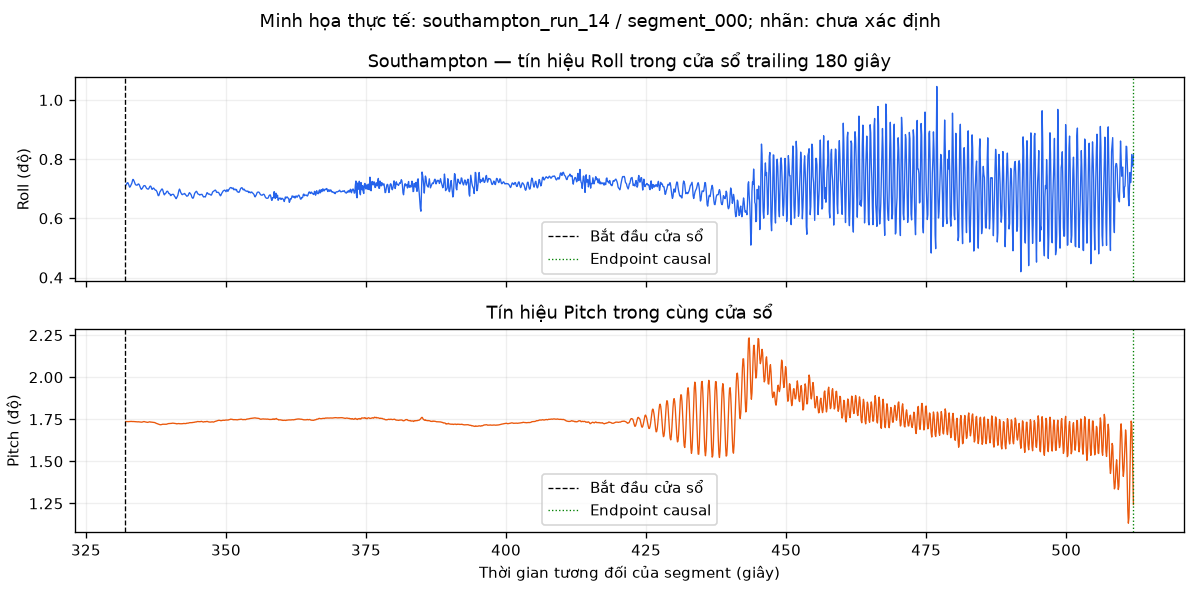

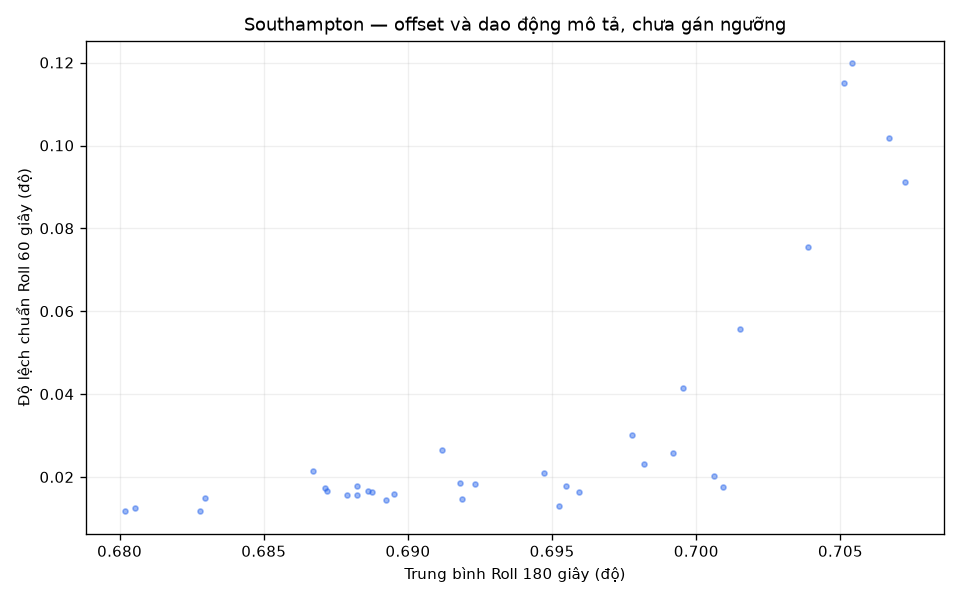

In [4]:
for figure_name in (f"{DATASET}_representative_window.png", f"{DATASET}_offset_vs_oscillation.png"):
    display(Image(filename=str(REPO_ROOT / "ml/data/labels/diagnostics" / figure_name)))

## Nhãn chưa xác định, review và giới hạn

Các cửa sổ đầu ra hiện ở trạng thái `UNLABELED`, nguồn `UNKNOWN`; review queue lấy mẫu thời gian phân bố đều theo session. Không có quyết định người duyệt nào được giả lập. Chỉ Run 14 hỗ trợ nhãn cửa sổ 180 giây; 34 endpoint chồng lấn của một run không chứng minh được độ lặp giữa nhiều run.

## Giải thích kỹ thuật phục vụ vấn đáp

**Em đã làm gì?** Lọc các endpoint 180 giây có đủ 23 feature angle-only `VALID` từ feature tables. **Vì sao?** Đảm bảo có đủ lịch sử cho offset/growth và không vượt ranh giới phiên. **Phương pháp?** Tái sử dụng loader labeling, thống kê mô tả, hình từ dữ liệu processed. **Kết quả thực nghiệm?** Notebook hiển thị số endpoint, session, thống kê và trạng thái nhãn đọc từ artifact hiện hành. **Nếu tự gán lớp từ cực trị?** Sẽ biến percentile nội bộ thành ngưỡng không có cơ sở và tạo circular labeling. **Giới hạn?** Chưa có ground truth, ngưỡng hazard hoặc human review độc lập.